# 12 · La distribución de la media muestral

Cada muestra produce una media distinta. ¿Cómo varía la media muestral de una muestra a otra? Simulamos muchas muestras y comparamos con la teoría: $\bar X_n$ tiene media $\mu$ y desviación estándar $\sigma/\sqrt n$ (el **error estándar**), y para poblaciones normales su ley es exactamente $N(\mu,\sigma^2/n)$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import expon, norm

rng = np.random.default_rng(2026)

## 1. Una muestra

Tomamos una muestra de tamaño $n=30$ de una población $N(10,5^2)$.

In [2]:
mu, sigma, n = 10, 5, 30
muestra = pd.Series(rng.normal(mu, sigma, size=n))
print(f"media de la muestra: {muestra.mean():.4f}")
print(f"desviación estándar de la muestra (ddof=1): {muestra.std(ddof=1):.4f}")

media de la muestra: 9.9846
desviación estándar de la muestra (ddof=1): 4.0417


## 2. Muchas muestras

Repetimos el muestreo $10\,000$ veces y guardamos cada media. Con NumPy basta generar una matriz de $10\,000\times 30$ y promediar por filas.

In [3]:
M = 10_000
medias = pd.Series(rng.normal(mu, sigma, size=(M, n)).mean(axis=1), name="media muestral")
medias.head()

0    12.330629
1     9.192461
2     9.481152
3    10.658535
4    10.811415
Name: media muestral, dtype: float64

media de las medias:   10.0086   (μ = 10)
desv. est. de las medias: 0.9072   (σ/√n = 0.9129)


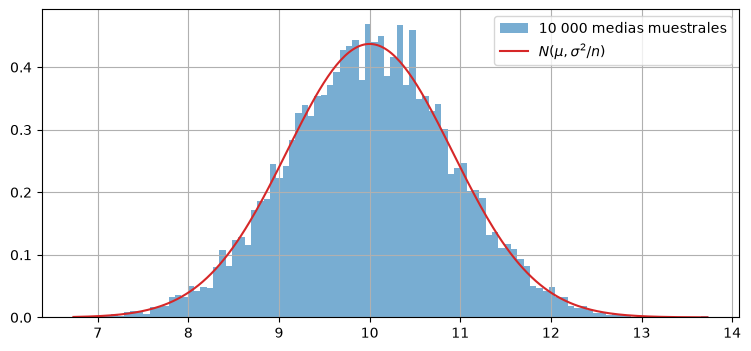

In [4]:
print(f"media de las medias:   {medias.mean():.4f}   (μ = {mu})")
print(f"desv. est. de las medias: {medias.std():.4f}   (σ/√n = {sigma / np.sqrt(n):.4f})")

fig, ax = plt.subplots(figsize=(9, 4))
medias.hist(bins=100, density=True, ax=ax, alpha=0.6, label="10 000 medias muestrales")
x = np.linspace(medias.min(), medias.max(), 300)
ax.plot(x, norm.pdf(x, mu, sigma / np.sqrt(n)), color="tab:red", label=r"$N(\mu,\sigma^2/n)$")
ax.legend()
plt.show()

## 3. El efecto del tamaño de muestra

El error estándar $\sigma/\sqrt n$ decrece como $1/\sqrt n$: para reducir la dispersión a la mitad hay que cuadruplicar la muestra.

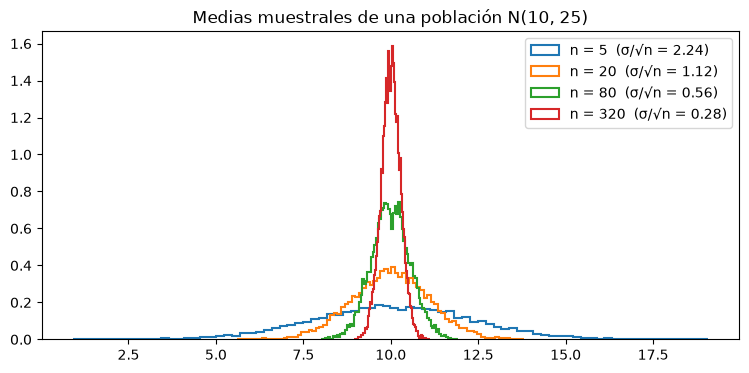

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
for n_ in [5, 20, 80, 320]:
    m = rng.normal(mu, sigma, size=(M, n_)).mean(axis=1)
    ax.hist(m, bins=80, density=True, histtype="step", lw=1.5, label=f"n = {n_}  (σ/√n = {sigma / np.sqrt(n_):.2f})")
ax.legend()
ax.set_title("Medias muestrales de una población N(10, 25)")
plt.show()

## 4. Poblaciones no normales

Si la población no es normal, $\bar X_n$ ya no es exactamente normal, pero el **teorema central del límite** garantiza que $\sqrt n(\bar X_n-\mu)/\sigma$ converge en ley a $N(0,1)$. Con una población exponencial (muy asimétrica, $\mu=\sigma=1$):

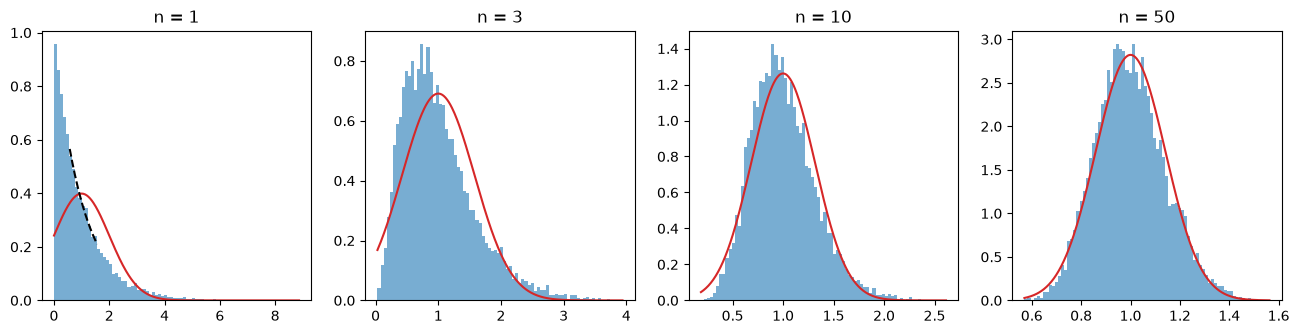

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, n_ in zip(axes, [1, 3, 10, 50]):
    m = rng.exponential(1.0, size=(M, n_)).mean(axis=1)
    ax.hist(m, bins=80, density=True, alpha=0.6)
    x = np.linspace(max(m.min(), 1e-3), m.max(), 300)
    ax.plot(x, norm.pdf(x, 1, 1 / np.sqrt(n_)), color="tab:red")
    ax.set_title(f"n = {n_}")
axes[0].plot(x, expon.pdf(x), color="k", ls="--")
plt.show()

## Ejercicios

1. Para la población $N(10,25)$ y $n=30$, estima por simulación $\mathbb P(|\bar X_n-10|<1)$ y compárala con $2\Phi(\sqrt{30}/5)-1$.
2. Repite la sección 2 con la desviación estándar muestral en lugar de la media. ¿Su ley es simétrica?